# 07 · Monitorización del modelo · Data drift y model drift (Objetivo 2)

## ¿Qué queremos conseguir?
El modelo del notebook 06 predice cuántos minutos tardará un pedido. Lo entrenamos con pedidos de **2023-2025**. Pero un restaurante cambia: llega una carta nueva, se contrata (o se despide) personal, sube la demanda, cambian las costumbres de los clientes… Un modelo no se entera de nada de eso: **sigue aplicando lo que aprendió**. Si el mundo ha cambiado, empezará a equivocarse **sin avisar**.

Este notebook responde a tres preguntas:
1. **¿Ha cambiado lo que le llega al modelo?** (*data drift*, se puede saber el mismo día, sin esperar al tiempo real).
2. **¿Ha empeorado el modelo?** (*model drift*, se sabe cuando ya conocemos cuánto tardó de verdad cada pedido).
3. **¿Qué hacemos?** Una regla de decisión, un **reentrenamiento** probado con datos y una **estrategia de monitorización** para el día a día.

Lo demostramos con un **segundo lote de datos** (enero-junio de 2026) que generamos en **dos versiones** con el mismo generador:

| Lote | Qué representa | Qué esperamos que diga la monitorización |
|---|---|---|
| `2026h1_control` | El restaurante sigue funcionando igual que en 2023-2025. | **Mantener** el modelo (si saltara una alarma, sería una *falsa alarma*). |
| `2026h1_drift` | A partir del **1 de marzo** cambian cosas (carta, personal, demanda, delivery). | **Reentrenar**, y que se vea **desde qué mes**. |

> **Honestidad sobre los datos:** los dos lotes son **sintéticos**. Los cambios del lote `drift` los hemos puesto nosotros a propósito (están descritos en `data/generar_lote_drift.py`) para poder comprobar que la monitorización los detecta. No demuestra cómo cambian los restaurantes reales; demuestra que **el método funciona cuando algo cambia y se calla cuando nada cambia**.

---
## Guía rápida de conceptos

| Concepto | Qué significa, en sencillo |
|---|---|
| **Data drift** (deriva de los datos) | Los **datos de entrada** del lote nuevo ya no se parecen a los del entrenamiento (por ejemplo, ahora hay menos cocineros). Se detecta **sin** el tiempo real. |
| **Concept drift** (deriva del concepto) | Cambia la **relación** entre entradas y resultado: con las mismas entradas, ahora el pedido **tarda otra cosa** (por ejemplo, el delivery tarda más). El modelo se equivoca aunque las entradas parezcan normales. |
| **Model drift** | El **error del modelo** sube. Es la consecuencia visible de los dos anteriores. Necesita el tiempo real, que llega con retraso. |
| **PSI** (*Population Stability Index*) | Un número que dice **cuánto se ha movido** una variable respecto a la referencia. **< 0,10** estable · **0,10-0,25** vigilar · **> 0,25** alerta. Es nuestra métrica principal. |
| **Test KS / chi²** | Tests estadísticos que confirman si dos distribuciones son distintas (KS para números, chi² para categorías). Los calculamos, pero **no decidimos con ellos**: con decenas de miles de pedidos *cualquier* diferencia, por pequeña que sea, sale «significativa». El PSI mide **cuánto** ha cambiado, que es lo que importa. |
| **Referencia** | Los datos con los que se entrenó el modelo (el 80 % más antiguo del lote 1). Todo se compara contra ellos. |
| **Modelo vigente** | La versión de MLflow con el alias `actual` (el que usa la API). |
| **Candidato** | Un modelo reentrenado que **todavía no está en producción**: se prueba y solo se promueve si mejora. |

---
## 0. Configuración y funciones

Igual que en el notebook 06: todo lo que se puede cambiar está en **una sola celda** (rutas, umbrales, nombres) y las funciones llevan una descripción. La limpieza del lote nuevo y las métricas de drift están en la carpeta `monitorizacion/` del repositorio, para poder reutilizarlas fuera del notebook.

In [1]:
from __future__ import annotations

import os
import sys
import warnings
from datetime import datetime
from pathlib import Path
from zoneinfo import ZoneInfo

import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from mlflow.models import infer_signature
from mlflow.tracking import MlflowClient
from sklearn.base import clone

warnings.filterwarnings("ignore", message="Hint: Inferred schema contains integer column")

# ---------- Código reutilizable del repositorio (carpeta monitorizacion/, en la raíz) ----------
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "monitorizacion").exists())
sys.path.insert(0, str(REPO))
from monitorizacion import drift as D                                     # noqa: E402  PSI, KS, chi², decisión
from monitorizacion.limpieza_pedidos import limpiar_pedidos, leer_raw     # noqa: E402  limpieza del notebook 02 como función

# ---------- Rutas: HDFS por WebHDFS (las variables de entorno las pone el contenedor de Docker) ----------
HOST = os.environ.get("HDFS_WEBHDFS_URL", "http://namenode:9870").replace("http://", "")
DATALAKE = os.environ.get("DATALAKE_URI", f"webhdfs://{HOST}/datalake")           # raíz del data lake
OPT = {"user": os.environ.get("HDFS_USER", "root")} if DATALAKE.startswith("webhdfs") else None
RUTA_REFERENCIA = f"{DATALAKE}/clean/pedidos_tiempos_preparacion/pedidos_limpio.parquet"      # la deja el notebook 02
RUTA_RAW_LOTE1 = f"{DATALAKE}/raw/pedidos_tiempos_preparacion/02_pedidos_tiempos_preparacion.csv"
RUTA_RAW_LOTE = lambda lote: f"{DATALAKE}/raw/pedidos_tiempos_preparacion/lote={lote}/02_pedidos_tiempos_preparacion.csv"
LOTES = {"control": "2026h1_control", "drift": "2026h1_drift"}     # carpetas que crea scripts/ingesta_hdfs.sh (data/entrada/<lote>/)

# ---------- MLflow ----------
MLFLOW_URI = os.environ.get("MLFLOW_TRACKING_URI", "http://mlflow:5000")
NOMBRE_EXPERIMENTO = "smart-restaurant-monitorizacion-drift"             # carpeta propia: no mezcla con las pruebas del notebook 06
NOMBRE_MODELO = "smart_restaurant_regresion_tiempo_prep"                 # el mismo modelo registrado en el notebook 06
ALIAS_VIGENTE, ALIAS_CANDIDATO = "actual", "candidato"
MARCA_TIEMPO = datetime.now(ZoneInfo("Europe/Madrid")).strftime("%Y-%m-%d_%H-%M")

# ---------- Variables: EXACTAMENTE las del notebook 06 ----------
OBJETIVO = "tiempo_prep_minutos"
FORMATO_FECHA = "%d-%m-%Y"
FRACCION_ENTRENAMIENTO = 0.80
VARIABLES_NUMERICAS = ["n_platos", "num_platos_complejos", "complejidad_pedido", "cola_pedidos",
                       "cocineros_disponibles", "precipitacion_mm", "hora_dec", "dia_semana", "ingrediente_agotado"]
VARIABLES_CATEGORIA = ["canal", "prioridad_aux"]
VARIABLES = VARIABLES_NUMERICAS + VARIABLES_CATEGORIA
ETIQUETAS = {"n_platos": "nº de platos", "num_platos_complejos": "nº de platos complejos", "complejidad_pedido": "complejidad del pedido",
             "cola_pedidos": "pedidos en cola", "cocineros_disponibles": "cocineros disponibles", "precipitacion_mm": "lluvia (mm)",
             "hora_dec": "hora del día", "dia_semana": "día de la semana", "ingrediente_agotado": "ingrediente agotado",
             "canal": "canal", "prioridad_aux": "prioridad"}

# ---------- Reentrenamiento ----------
FRACCION_REENTRENO = 0.80          # del lote nuevo: el 80 % más antiguo para reentrenar, el 20 % más reciente para el examen
PESO_LOTE_NUEVO = 3.0              # en el candidato «ponderado», cada pedido nuevo pesa como 3 antiguos
MEJORA_MINIMA = 0.10               # el candidato debe bajar el MAE al menos un 10 % frente al modelo vigente en el examen nuevo
TOLERANCIA_R2 = 0.05               # ...y su R² no puede ser más de 0,05 peor que el de referencia
SESGO_MAXIMO = 1.0                 # ...y su sesgo (real − predicho) no puede pasar de ±1 minuto
PROMOVER_AUTOMATICAMENTE = False   # False: el candidato queda registrado con el alias «candidato» y una persona decide. True: pasa a «actual» si cumple.
RANDOM_STATE = 42

# ---------- Colores de Smart-Restaurant ----------
AZUL, NARANJA, GRIS_AZULADO, MELOCOTON, VERDE = "#1F3A44", "#F28C38", "#5C808E", "#FFE0C2", "#6FA8A0"
CMAP_SEC = LinearSegmentedColormap.from_list("sr_sec", ["#FFFFFF", MELOCOTON, NARANJA, AZUL])
COLOR_NIVEL = {"estable": VERDE, "vigilar": NARANJA, "alerta": "#C0392B"}
COLOR_DECISION = {"mantener": VERDE, "vigilar": NARANJA, "reentrenar": "#C0392B"}
sns.set_theme(style="whitegrid", font="DejaVu Sans")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 11,
                     "axes.edgecolor": GRIS_AZULADO, "axes.labelcolor": AZUL, "text.color": AZUL})
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

In [2]:
def validar(condicion: bool, mensaje: str) -> None:
    """Comprueba algo que DEBE cumplirse. Si falla, el notebook se detiene con un mensaje claro."""
    assert condicion, f"FALLO: {mensaje}"
    print(f"OK · {mensaje}")


def conectar_mlflow(uri: str, nombre_experimento: str):
    """Conecta con el servidor MLflow y selecciona (o crea) el experimento. Falla rápido y con un mensaje claro."""
    try:
        requests.get(f"{uri}/health", timeout=5).raise_for_status()
    except Exception as error:
        raise RuntimeError(f"No se puede conectar con MLflow en {uri}. ¿Está arrancado el servicio? "
                           "Desde la carpeta docker/ ejecuta: docker compose up -d --build") from error
    mlflow.set_tracking_uri(uri)
    return mlflow.set_experiment(nombre_experimento)


def preparar(df: pd.DataFrame) -> pd.DataFrame:
    """Deja una tabla limpia lista para el modelo: fecha como fecha real, categorías como texto y orden cronológico."""
    df = df.copy()
    df["fecha"] = pd.to_datetime(df["fecha"], format=FORMATO_FECHA)
    df[VARIABLES_CATEGORIA] = df[VARIABLES_CATEGORIA].astype(str)
    return df.sort_values(["fecha", "hora_dec"]).reset_index(drop=True)


def fecha_de_corte(df: pd.DataFrame, fraccion: float) -> pd.Timestamp:
    """Día a partir del cual los pedidos pasan a ser de «examen» (la misma regla que en el notebook 06)."""
    return df.sort_values(["fecha", "hora_dec"]).reset_index(drop=True).loc[int(len(df) * fraccion), "fecha"]


def cargar_lote_raw(ruta: str) -> tuple[pd.DataFrame, dict]:
    """Lee un lote RAW de HDFS, le aplica la limpieza del notebook 02 y devuelve (pedidos limpios, resumen de lo descartado)."""
    limpio, resumen = limpiar_pedidos(leer_raw(ruta, storage_options=OPT))
    return preparar(limpio), resumen


def figura_psi(tabla: pd.DataFrame, titulo: str) -> plt.Figure:
    """Barras: eje y = variable; eje x = PSI. Las líneas marcan los umbrales (0,10 vigilar · 0,25 alerta). Gris = solo informativa."""
    t = tabla.copy()
    t["etiqueta"] = t["variable"].map(ETIQUETAS) + np.where(t["decide"], "", " (solo informativa)")
    fig, ax = plt.subplots(figsize=(7.4, 4.4))
    colores = [COLOR_NIVEL[n] if d else "#B8C4C9" for n, d in zip(t["nivel"], t["decide"])]
    ax.barh(t["etiqueta"], t["psi"], color=colores)
    for umbral, texto in ((D.PSI_VIGILAR, "vigilar"), (D.PSI_ALERTA, "alerta")):
        ax.axvline(umbral, color=GRIS_AZULADO, linestyle="--", linewidth=1)
        ax.text(umbral, 0.02, f" {texto} ({umbral})", fontsize=8, color=GRIS_AZULADO, va="bottom", transform=ax.get_xaxis_transform())
    ax.invert_yaxis()
    ax.set(title=titulo, xlabel="PSI (cuánto se ha movido la variable)", ylabel="")
    fig.tight_layout()
    return fig


def figura_distribuciones(ref: pd.DataFrame, nuevo: pd.DataFrame, variables: list[str], etiqueta_nuevo: str) -> plt.Figure:
    """Una gráfica por variable: la forma de la distribución en el entrenamiento (azul) frente al lote nuevo (naranja)."""
    fig, ejes = plt.subplots(1, len(variables), figsize=(4.2 * len(variables), 3.4))
    for ax, v in zip(np.atleast_1d(ejes), variables):
        if v in VARIABLES_CATEGORIA:
            tabla = pd.concat({"entrenamiento": ref[v].value_counts(normalize=True),
                               etiqueta_nuevo: nuevo[v].value_counts(normalize=True)}, axis=1).fillna(0)
            tabla.plot.bar(ax=ax, color=[AZUL, NARANJA], rot=0, width=0.7)
            ax.set(ylabel="% de pedidos", xlabel="")
        else:
            cortes = np.histogram_bin_edges(pd.concat([ref[v], nuevo[v]]), bins=25)
            ax.hist(ref[v], bins=cortes, density=True, alpha=0.65, color=AZUL, label="entrenamiento")
            ax.hist(nuevo[v], bins=cortes, density=True, alpha=0.65, color=NARANJA, label=etiqueta_nuevo)
            ax.set(ylabel="densidad", xlabel="")
        ax.set_title(ETIQUETAS[v]); ax.legend(fontsize=8)
    fig.tight_layout()
    return fig


def figura_real_vs_predicho(reales, predichos, titulo: str) -> plt.Figure:
    """Cada punto es un pedido: eje x = minutos reales; eje y = minutos predichos. Cuanto más pegada a la diagonal, mejor."""
    fig, ax = plt.subplots(figsize=(5.2, 4.6))
    densidad = ax.hexbin(reales, predichos, gridsize=45, bins="log", cmap=CMAP_SEC, mincnt=1)
    ax.plot([3, 60], [3, 60], linestyle="--", color=GRIS_AZULADO, label="predicción perfecta")
    ax.set(title=titulo, xlabel="tiempo real (minutos)", ylabel="tiempo predicho (minutos)", xlim=(3, 60), ylim=(3, 60))
    ax.legend(loc="upper left", fontsize=8)
    fig.colorbar(densidad, ax=ax, label="nº de pedidos (escala logarítmica)")
    fig.tight_layout()
    return fig


def figura_seguimiento(seguimientos: dict[str, pd.DataFrame], mae_ref: float) -> plt.Figure:
    """MAE mes a mes de cada lote. Líneas: el MAE de referencia y los umbrales de «vigilar» y «alerta»."""
    fig, ax = plt.subplots(figsize=(8, 4.2))
    estilos = {"control": (VERDE, "o"), "drift": ("#C0392B", "s")}
    for clave, tabla in seguimientos.items():
        ax.plot(tabla["mes"], tabla["mae"], marker=estilos[clave][1], color=estilos[clave][0], linewidth=2, label=f"lote {clave}")
    ax.axhline(mae_ref, color=AZUL, linewidth=1.2, label=f"MAE de referencia ({mae_ref:.2f})")
    ax.axhline(mae_ref * (1 + D.MAE_VIGILAR), color=NARANJA, linestyle="--", linewidth=1, label=f"vigilar (+{D.MAE_VIGILAR:.0%})")
    ax.axhline(mae_ref * (1 + D.MAE_ALERTA), color="#C0392B", linestyle="--", linewidth=1, label=f"alerta (+{D.MAE_ALERTA:.0%})")
    ax.set(title="Error del modelo vigente mes a mes", xlabel="mes de 2026", ylabel="MAE (minutos)", ylim=(0, None))
    ax.legend(fontsize=8, ncol=2)
    fig.tight_layout()
    return fig


def figura_candidatos(tabla: pd.DataFrame) -> plt.Figure:
    """Barras: MAE de cada modelo con el examen del lote nuevo (más bajo = mejor). Línea: MAE de referencia."""
    fig, ax = plt.subplots(figsize=(7.4, 4.0))
    colores = [GRIS_AZULADO if n.startswith("vigente") else AZUL for n in tabla.index]
    etiquetas = [n.replace(" (", "\n(") if n.startswith("vigente") else n.replace(" ", "\n", 1) for n in tabla.index]
    ax.bar(etiquetas, tabla["mae_examen_nuevo"], color=colores)
    for i, v in enumerate(tabla["mae_examen_nuevo"]):
        ax.text(i, v, f"{v:.2f}", ha="center", va="bottom", fontsize=9)
    ax.axhline(MAE_REF, color=NARANJA, linestyle="--", label=f"MAE en el examen original ({MAE_REF:.2f})")
    ax.set(title="¿Quién acierta mejor con los pedidos más recientes?", ylabel="MAE (minutos)", xlabel="")
    ax.legend(fontsize=8)
    fig.tight_layout()
    return fig

---
## 1. La referencia: el modelo vigente y los datos con los que se entrenó

**Qué hacemos:**
1. Conectamos con MLflow y cargamos el modelo con el alias `actual` (el que usa la API).
2. Cargamos los pedidos limpios del lote 1 (`pedidos_limpio.parquet`) y repetimos **la misma separación por fecha** del notebook 06: el 80 % más antiguo es el **entrenamiento** (lo que el modelo vio) y el 20 % más reciente, el **examen**.
3. Leemos el **MAE que obtuvo en su examen original** (está guardado en MLflow): es la nota contra la que compararemos.

Si no hay modelo con alias `actual`, hay que ejecutar antes el notebook 06.

In [3]:
experimento = conectar_mlflow(MLFLOW_URI, NOMBRE_EXPERIMENTO)
cliente = MlflowClient()

# 1) El modelo vigente (alias «actual») y la nota que sacó en su examen original
try:
    version_vigente = cliente.get_model_version_by_alias(NOMBRE_MODELO, ALIAS_VIGENTE)
except Exception as error:
    raise RuntimeError(f"No hay ningún modelo '{NOMBRE_MODELO}' con alias '{ALIAS_VIGENTE}'. Ejecuta antes el notebook 06.") from error
modelo_vigente = mlflow.sklearn.load_model(f"models:/{NOMBRE_MODELO}@{ALIAS_VIGENTE}")
notas_ref = cliente.get_run(version_vigente.run_id).data.metrics
MAE_REF, R2_REF = notas_ref["test_mae"], notas_ref["test_r2"]
print(f"Modelo vigente: versión {version_vigente.version} ({version_vigente.description[:60] if version_vigente.description else 'sin descripción'}…)")
print(f"Nota en su examen original: MAE {MAE_REF:.3f} min · R² {R2_REF:.3f}")

# 2) Los pedidos del lote 1 y la misma separación por fecha que el notebook 06
pedidos = preparar(pd.read_parquet(RUTA_REFERENCIA, storage_options=OPT))
corte = fecha_de_corte(pedidos, FRACCION_ENTRENAMIENTO)
entrenamiento, prueba = pedidos[pedidos["fecha"] < corte], pedidos[pedidos["fecha"] >= corte]
print(f"Entrenamiento (referencia): {len(entrenamiento):,} pedidos ({entrenamiento['fecha'].min():%d-%m-%Y} → {entrenamiento['fecha'].max():%d-%m-%Y})")
print(f"Examen original:            {len(prueba):,} pedidos ({prueba['fecha'].min():%d-%m-%Y} → {prueba['fecha'].max():%d-%m-%Y})")

# 3) Comprobación: con estos datos y este modelo debemos obtener la misma nota que guardó el notebook 06
mae_recalculado = D.metricas(prueba[OBJETIVO], modelo_vigente.predict(prueba[VARIABLES]))["mae"]
validar(abs(mae_recalculado - MAE_REF) < 0.01, f"el modelo y los datos de referencia coinciden con los del notebook 06 (MAE {mae_recalculado:.3f} vs {MAE_REF:.3f})")

Modelo vigente: versión 2 (Random Forest. Entrenado el 2026-11-25_09-55 con pedidos has…)
Nota en su examen original: MAE 2.127 min · R² 0.884
Entrenamiento (referencia): 90,300 pedidos (01-01-2023 → 04-06-2025)
Examen original:            22,663 pedidos (05-06-2025 → 31-12-2025)
OK · el modelo y los datos de referencia coinciden con los del notebook 06 (MAE 2.127 vs 2.127)


---
## 2. El segundo lote: ingesta, limpieza y control de calidad

**Qué hacemos:** leemos de HDFS los dos lotes nuevos (los dejó `scripts/ingesta_hdfs.sh` en `/datalake/raw/pedidos_tiempos_preparacion/lote=<nombre>/`) y les aplicamos **la misma limpieza que al lote 1**. Es importante: si limpiáramos distinto, las diferencias podrían venir de **cómo limpiamos** y no de que los datos hayan cambiado.

Comprobamos dos cosas:
- **Que la limpieza copiada funciona igual que la original:** aplicada al lote 1 debe dar exactamente las filas del `pedidos_limpio.parquet` del notebook 02.
- **La calidad del lote nuevo:** cuántas filas se descartan. Si de pronto se descartaran muchas más que en el lote 1, sería una señal de que **algo falla en la captura de datos**, aunque los valores buenos estén bien. Por eso este porcentaje también se vigila.

In [4]:
# La limpieza copiada tiene que reproducir el notebook 02 sobre el lote 1
lote1_limpio, resumen_lote1 = cargar_lote_raw(RUTA_RAW_LOTE1)
validar(len(lote1_limpio) == len(pedidos), f"la limpieza reproduce el notebook 02: {len(lote1_limpio):,} pedidos limpios en el lote 1")

# Los dos lotes nuevos, con la misma limpieza
lotes, resumenes = {}, {"lote 1 (2023-2025)": resumen_lote1}
for clave, nombre in LOTES.items():
    lotes[clave], resumenes[f"lote 2 · {clave}"] = cargar_lote_raw(RUTA_RAW_LOTE(nombre))
    print(f"{clave:8s} -> {len(lotes[clave]):,} pedidos limpios ({lotes[clave]['fecha'].min():%d-%m-%Y} → {lotes[clave]['fecha'].max():%d-%m-%Y})")

calidad = pd.DataFrame(resumenes).T[["filas_raw", "filas_limpias", "pct_descartado", "duplicados_eliminados",
                                      "fechas_en_formato_mdy", "tiempo_en_hhmm_convertidos", "sin_n_platos", "sin_tiempo", "sin_carga_cocina"]]
display(calidad)
for clave in LOTES:
    validar(lotes[clave]["fecha"].min() > pedidos["fecha"].max(), f"el lote {clave} es posterior a todo el lote 1 (no se mezclan épocas)")
    validar(abs(resumenes[f"lote 2 · {clave}"]["pct_descartado"] - resumen_lote1["pct_descartado"]) < 3, f"el lote {clave} descarta un % de filas parecido al lote 1 (calidad de captura estable)")

OK · la limpieza reproduce el notebook 02: 112,963 pedidos limpios en el lote 1
control  -> 19,310 pedidos limpios (01-01-2026 → 30-06-2026)
drift    -> 21,183 pedidos limpios (01-01-2026 → 30-06-2026)


,filas_raw,filas_limpias,pct_descartado,duplicados_eliminados,fechas_en_formato_mdy,tiempo_en_hhmm_convertidos,sin_n_platos,sin_tiempo,sin_carga_cocina
lote 1 (2023-2025),"115,590.000","112,963.000",2.270,600.000,"1,763.000",921.000,532.000,514.000,981.000
lote 2 · control,"19,958.000","19,310.000",3.250,300.000,297.000,162.000,93.000,80.000,175.000
lote 2 · drift,"21,856.000","21,183.000",3.080,300.000,325.000,155.000,94.000,105.000,174.000


OK · el lote control es posterior a todo el lote 1 (no se mezclan épocas)
OK · el lote control descarta un % de filas parecido al lote 1 (calidad de captura estable)
OK · el lote drift es posterior a todo el lote 1 (no se mezclan épocas)
OK · el lote drift descarta un % de filas parecido al lote 1 (calidad de captura estable)


---
## 3. Data drift: ¿han cambiado las entradas?

**Qué hacemos:** comparamos, variable a variable, el lote nuevo contra el **entrenamiento**. Para cada una calculamos el **PSI** (cuánto se ha movido), un test estadístico (KS o chi²) y cómo ha cambiado el valor típico.

**Cómo leer la tabla:** `nivel` es *estable* (PSI < 0,10), *vigilar* (0,10 a 0,25) o *alerta* (> 0,25). La **lluvia** sale marcada como *solo informativa*: es un dato del **día** (todos los pedidos de ese día comparten el mismo valor) y además es estacional, así que comparar seis meses sueltos contra tres años completos no es justo. Se muestra, pero no decide.

Esto **no usa el tiempo real**: se puede calcular el mismo día que llegan los pedidos. Es la **alerta temprana**.

In [5]:
tablas_drift = {clave: D.data_drift(entrenamiento, lote, VARIABLES_NUMERICAS, VARIABLES_CATEGORIA) for clave, lote in lotes.items()}
columnas = ["variable", "tipo", "psi", "nivel", "test", "estadistico", "p_valor", "referencia", "nuevo", "detalle", "decide"]

print("=== Lote CONTROL (todo debería seguir igual) ===")
display(tablas_drift["control"][columnas])
print("=== Lote DRIFT (algo ha cambiado desde marzo) ===")
display(tablas_drift["drift"][columnas])

=== Lote CONTROL (todo debería seguir igual) ===


,variable,tipo,psi,nivel,test,estadistico,p_valor,referencia,nuevo,detalle,decide
0,num_platos_complejos,numérica,0.028,estable,KS,0.072,0.000,0.832,0.686,media,True
1,complejidad_pedido,numérica,0.017,estable,KS,0.055,0.000,4.590,4.432,media,True
2,precipitacion_mm,numérica,0.007,estable,KS,0.089,0.000,2.533,2.675,media,False
3,cola_pedidos,numérica,0.004,estable,KS,0.023,0.000,7.647,7.362,media,True
4,dia_semana,numérica,0.001,estable,KS,0.007,0.461,4.850,4.856,media,True
5,hora_dec,numérica,0.001,estable,KS,0.005,0.822,17.213,17.203,media,True
6,n_platos,numérica,0.000,estable,KS,0.007,0.416,3.408,3.425,media,True
7,canal,categórica,0.000,estable,chi²,4.230,0.121,0.283,0.290,% de «delivery»,True
8,cocineros_disponibles,numérica,0.000,estable,KS,0.005,0.898,4.821,4.830,media,True
9,ingrediente_agotado,numérica,0.000,estable,KS,0.002,1.000,0.027,0.029,media,True


=== Lote DRIFT (algo ha cambiado desde marzo) ===


,variable,tipo,psi,nivel,test,estadistico,p_valor,referencia,nuevo,detalle,decide
0,cocineros_disponibles,numérica,0.269,alerta,KS,0.223,0.000,4.821,4.132,media,True
1,complejidad_pedido,numérica,0.195,vigilar,KS,0.236,0.000,4.590,5.250,media,True
2,num_platos_complejos,numérica,0.070,estable,KS,0.107,0.000,0.832,1.106,media,True
3,canal,categórica,0.058,estable,chi²,"1,011.837",0.000,0.511,0.404,% de «mesa»,True
4,n_platos,numérica,0.027,estable,KS,0.066,0.000,3.408,3.685,media,True
5,precipitacion_mm,numérica,0.007,estable,KS,0.084,0.000,2.533,2.669,media,False
6,cola_pedidos,numérica,0.007,estable,KS,0.033,0.000,7.647,8.027,media,True
7,dia_semana,numérica,0.000,estable,KS,0.003,0.990,4.850,4.851,media,True
8,hora_dec,numérica,0.000,estable,KS,0.005,0.746,17.213,17.200,media,True
9,ingrediente_agotado,numérica,0.000,estable,KS,0.003,0.999,0.027,0.030,media,True


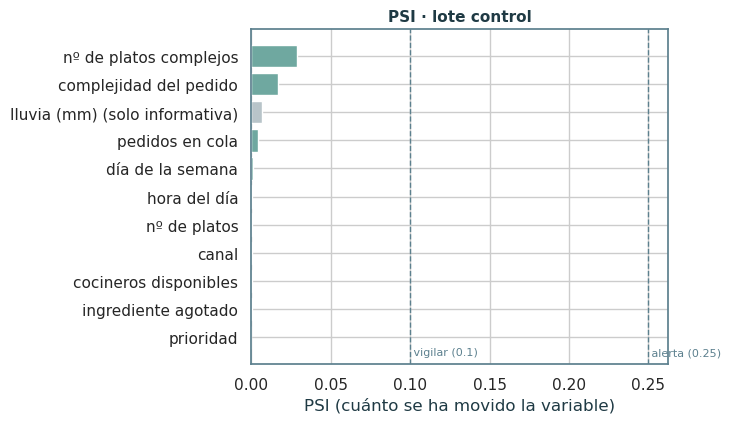

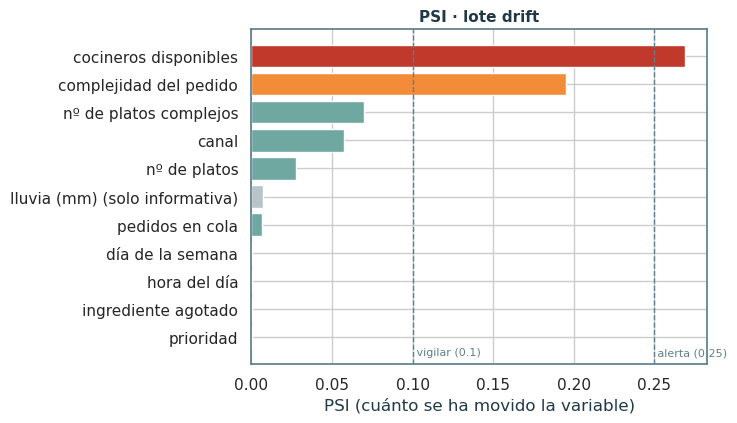

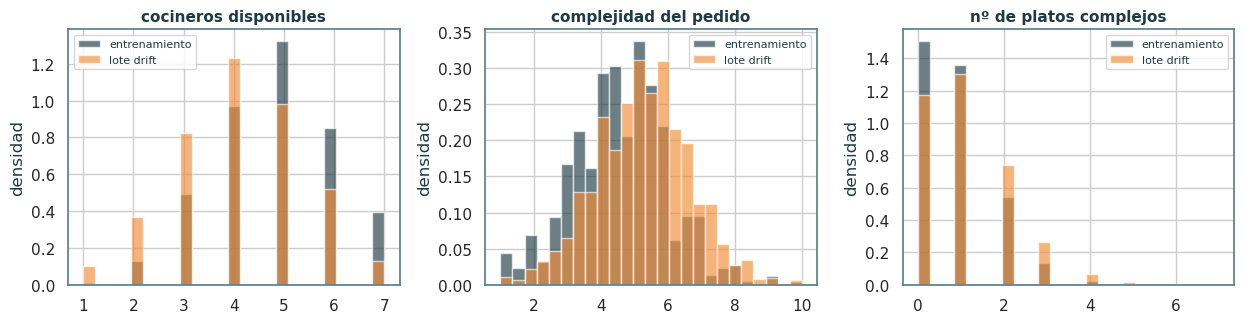

In [6]:
fig = figura_psi(tablas_drift["control"], "PSI · lote control")
plt.show()
fig = figura_psi(tablas_drift["drift"], "PSI · lote drift")
plt.show()

# Cómo ha cambiado la forma de las tres variables que más se han movido (en el lote drift)
peores = list(tablas_drift["drift"][tablas_drift["drift"]["decide"]]["variable"].head(3))
figura_distribuciones(entrenamiento, lotes["drift"], peores, "lote drift")
plt.show()

**Qué vemos:** en el lote *control* todas las barras están muy por debajo de 0,10: los pedidos se parecen a los del entrenamiento. En el lote *drift* se disparan las variables que tocamos a propósito: **cocineros disponibles** (se redujo la plantilla; es la única en *alerta*) y **complejidad del pedido** (carta más difícil, en *vigilar*). El **canal** (más delivery) y los **platos complejos** también se mueven, pero aquí quedan por debajo de 0,10 porque el semestre mezcla **dos meses normales con cuatro cambiados**: el cambio se **diluye**. Esa es una razón para monitorizar **mes a mes** (apartado 6) y no solo por lotes grandes. Los **pedidos en cola** y el resto casi no cambian.

> **Un detalle importante:** el PSI avisa de que las entradas han cambiado, pero **no dice si el modelo ha empeorado**. Para eso hace falta el tiempo real (siguiente apartado).

---
## 4. Model drift: ¿ha empeorado el modelo?

**Qué hacemos:** pasamos los pedidos del lote nuevo por el **modelo vigente** (sin reentrenarlo) y comparamos lo que predice con lo que tardó **de verdad** cada pedido. Medimos:
- **MAE:** error medio en minutos (más bajo = mejor).
- **RMSE:** como el MAE, pero castiga más los errores grandes.
- **R²:** qué parte de las variaciones del tiempo explica el modelo (1 = todo).
- **Sesgo:** media de *real − predicho*. Si es **positivo**, el modelo se **queda corto**: promete menos minutos de los que luego tarda el pedido. Para un cliente es el peor error (le dices 20 min y tarda 28).

Comparamos el MAE con el de su examen original (**MAE de referencia**) y aplicamos los umbrales: hasta **+15 %** normal, **+15 % a +30 %** vigilar, más de **+30 %** alerta.

,mae,rmse,r2,sesgo,subida_mae,nivel
control,2.050,2.648,0.874,0.026,-0.036,estable
drift,3.925,5.220,0.794,3.081,0.846,alerta
examen original (lote 1),2.127,2.733,0.884,0.031,0.000,—


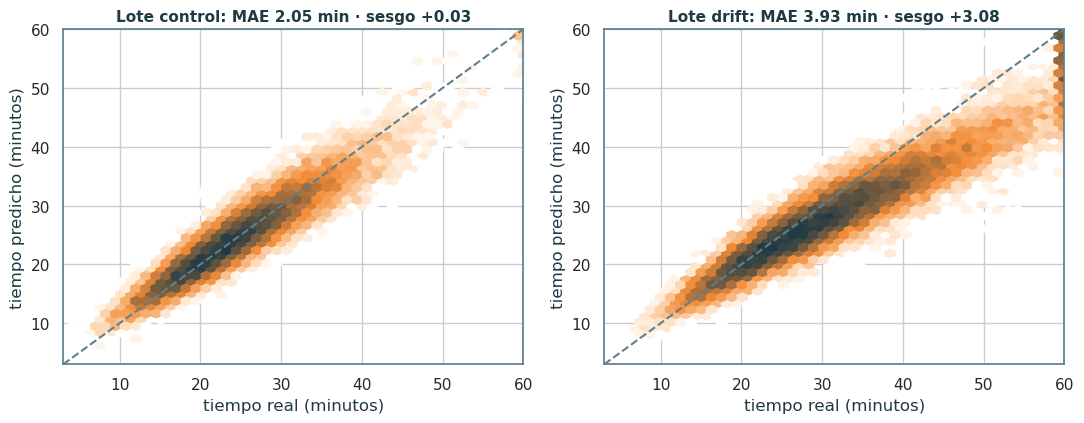

In [7]:
resultados_modelo = {clave: D.model_drift(modelo_vigente, lote[VARIABLES], lote[OBJETIVO], MAE_REF) for clave, lote in lotes.items()}

comparacion = pd.DataFrame({clave: {k: v for k, v in r.items() if k != "predicho"} for clave, r in resultados_modelo.items()}).T
comparacion.loc["examen original (lote 1)"] = {**D.metricas(prueba[OBJETIVO], modelo_vigente.predict(prueba[VARIABLES])),
                                              "mae_referencia": MAE_REF, "subida_mae": 0.0, "nivel": "—"}
display(comparacion[["mae", "rmse", "r2", "sesgo", "subida_mae", "nivel"]])

fig, ejes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, clave in zip(ejes, ["control", "drift"]):
    ax.hexbin(lotes[clave][OBJETIVO], resultados_modelo[clave]["predicho"], gridsize=45, bins="log", cmap=CMAP_SEC, mincnt=1)
    ax.plot([3, 60], [3, 60], linestyle="--", color=GRIS_AZULADO)
    ax.set(title=f"Lote {clave}: MAE {resultados_modelo[clave]['mae']:.2f} min · sesgo {resultados_modelo[clave]['sesgo']:+.2f}",
           xlabel="tiempo real (minutos)", ylabel="tiempo predicho (minutos)", xlim=(3, 60), ylim=(3, 60))
fig.tight_layout()
plt.show()

**Qué vemos:** con el lote *control* el modelo acierta igual que el día del examen (incluso algo mejor, por azar). Con el lote *drift* el error se **multiplica** y el sesgo es claramente positivo: **el modelo se queda corto**, porque aprendió que 4 platos tardan lo de 2023-2025 y ahora tardan más. En el gráfico, la nube del lote *drift* queda **por debajo de la diagonal**: predice menos de lo que tarda.

Esto es **concept drift** (cambió la relación entrada→tiempo, por ejemplo el delivery tarda más) combinado con **data drift** (hay menos cocineros y platos más difíciles, zonas que el modelo vio menos).

---
## 5. La decisión: mantener, vigilar o reentrenar

**Qué hacemos:** una regla escrita en `monitorizacion/drift.py` (función `decidir`), para que **no dependa de la opinión de nadie** en el momento:

| Situación | Decisión |
|---|---|
| El MAE sube **más de un 30 %** | **Reentrenar** (el modelo ya no sirve) |
| Aún no tenemos el tiempo real, pero **2 o más variables** tienen PSI > 0,25 | **Reentrenar** (alerta temprana: confirmar con datos etiquetados cuanto antes) |
| El MAE sube entre 15 % y 30 %, o alguna variable pasa de PSI 0,10 | **Vigilar** (revisar el siguiente mes con más atención) |
| Todo por debajo de los umbrales | **Mantener** |

Aplicamos la regla a cada lote y **comprobamos que el resultado es el esperado**: si el control saltara a «reentrenar», sería una falsa alarma; si el drift se quedara en «mantener», sería un fallo del detector.

In [8]:
decisiones = {clave: D.decidir(tablas_drift[clave], resultados_modelo[clave]) for clave in lotes}
for clave, d in decisiones.items():
    print(f"[{clave:8s}] {d}\n")

validar(decisiones["control"].accion == "mantener", "el lote CONTROL no provoca ninguna alarma (sin falsas alarmas)")
validar(decisiones["drift"].accion == "reentrenar", "el lote DRIFT provoca la decisión de reentrenar (el cambio se detecta)")

[control ] MANTENER: MAE 2.05 min (-4% vs referencia, nivel estable); 0 variable(s) con PSI > 0.25 y 0 entre 0.1 y 0.25 (la peor: num_platos_complejos, PSI 0.03)

[drift   ] REENTRENAR: MAE 3.93 min (+85% vs referencia, nivel alerta); 1 variable(s) con PSI > 0.25 y 1 entre 0.1 y 0.25 (la peor: cocineros_disponibles, PSI 0.27)

OK · el lote CONTROL no provoca ninguna alarma (sin falsas alarmas)
OK · el lote DRIFT provoca la decisión de reentrenar (el cambio se detecta)


---
## 6. Monitorización en el tiempo: ¿desde cuándo?

**Qué hacemos:** en la vida real no esperamos a tener seis meses: cada vez que se cierra un mes evaluamos sus pedidos y guardamos una fila. Repetimos el análisis **mes a mes** con el lote *control* y con el lote *drift*, y vemos **cuándo salta la alarma**.

Recuerda que el cambio del lote *drift* empieza el **1 de marzo**: enero y febrero son normales.

=== CONTROL ===


,mes,pedidos,variables_en_alerta,variables_a_vigilar,peor_variable,psi_max,mae,subida_mae,sesgo,decision
0,2026-01,3474,0,0,num_platos_complejos,0.028,2.103,-0.011,-0.041,mantener
1,2026-02,2946,0,0,num_platos_complejos,0.030,2.024,-0.048,0.038,mantener
2,2026-03,3199,0,0,dia_semana,0.015,2.083,-0.021,0.074,mantener
3,2026-04,3232,0,0,num_platos_complejos,0.039,2.012,-0.054,-0.057,mantener
4,2026-05,3399,0,0,num_platos_complejos,0.026,2.067,-0.028,0.092,mantener
5,2026-06,3060,0,0,num_platos_complejos,0.043,2.000,-0.059,0.056,mantener


=== DRIFT ===


,mes,pedidos,variables_en_alerta,variables_a_vigilar,peor_variable,psi_max,mae,subida_mae,sesgo,decision
0,2026-01,3460,0,0,num_platos_complejos,0.021,2.070,-0.027,-0.014,mantener
1,2026-02,2938,0,0,num_platos_complejos,0.034,2.078,-0.023,0.013,mantener
2,2026-03,3769,2,2,cocineros_disponibles,0.569,4.721,1.220,4.427,reentrenar
3,2026-04,3731,2,2,cocineros_disponibles,0.545,4.693,1.207,4.382,reentrenar
4,2026-05,3863,2,2,cocineros_disponibles,0.544,4.818,1.265,4.534,reentrenar
5,2026-06,3422,2,1,cocineros_disponibles,0.644,4.667,1.194,4.307,reentrenar


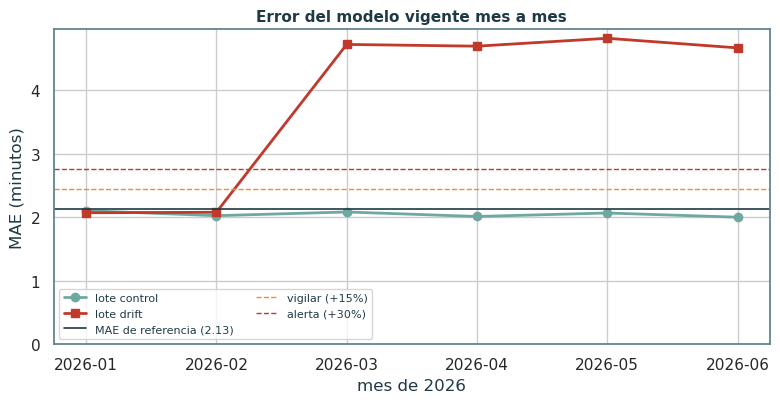

OK · en el control NINGÚN mes provoca alarma
OK · en el drift la alarma salta en el primer mes con cambio (2026-03)


In [9]:
seguimientos = {clave: D.seguimiento_mensual(entrenamiento, lote, VARIABLES_NUMERICAS, VARIABLES_CATEGORIA, modelo_vigente, OBJETIVO, MAE_REF)
                for clave, lote in lotes.items()}
columnas = ["mes", "pedidos", "variables_en_alerta", "variables_a_vigilar", "peor_variable", "psi_max", "mae", "subida_mae", "sesgo", "decision"]
print("=== CONTROL ==="); display(seguimientos["control"][columnas])
print("=== DRIFT ===");   display(seguimientos["drift"][columnas])

figura_seguimiento(seguimientos, MAE_REF)
plt.show()

validar((seguimientos["control"]["decision"] == "mantener").all(), "en el control NINGÚN mes provoca alarma")
primer_mes_alarma = seguimientos["drift"].loc[seguimientos["drift"]["decision"] == "reentrenar", "mes"].iloc[0]
validar(primer_mes_alarma == "2026-03", f"en el drift la alarma salta en el primer mes con cambio ({primer_mes_alarma})")

**Qué vemos:** enero y febrero siguen en *mantener*; **en marzo**, el mismo mes en el que cambiamos el funcionamiento, el MAE se dispara y la decisión pasa a *reentrenar*, y ya no vuelve atrás. Con una monitorización **mensual** el modelo habría estado dando malas estimaciones **un mes**, no seis.

> **Limitación que conviene decir en voz alta:** el drift de este ejemplo es **brusco** (un día cambia todo). En la realidad a menudo es **gradual** y cuesta más distinguirlo de la estacionalidad normal (más delivery en invierno, más gente en verano). Por eso la estrategia incluye un reentrenamiento **periódico** aunque no salte ninguna alarma (apartado 8).

---
## 7. Reentrenamiento: ¿qué datos usamos y mejora de verdad?

**Qué hacemos:** como la decisión es *reentrenar*, probamos **cuatro formas** de hacerlo y nos quedamos con la que mejor funcione **con pedidos que ningún modelo ha visto**.

**El examen:** del lote *drift* separamos **por fecha** el 20 % más reciente (último tramo de la primavera). Ningún candidato lo ve al entrenar. Es el mismo criterio que en el notebook 06: aprender del pasado y examinarse con «el futuro».

| Candidato | Con qué datos aprende | Idea |
|---|---|---|
| **Acumulado** | lote 1 completo + el 80 % antiguo del lote nuevo | Más datos, pero mezcla comportamiento viejo y nuevo. |
| **Acumulado ponderado** | lo mismo que el acumulado, pero cada pedido nuevo pesa ×3 | Intermedio: conserva el histórico, pero hace más caso a lo reciente. |
| **Solo lote nuevo** | solo el 80 % antiguo del lote nuevo (desde enero) | Olvida el pasado, pero incluye enero y febrero, que eran «normales». |
| **Desde la alarma** | solo los pedidos del lote nuevo **desde el mes en que saltó la alarma** (apartado 6) | Aprende solo del funcionamiento nuevo. Usa lo que nos dijo la monitorización. |

Todos usan **el mismo pipeline y los mismos ajustes del Random Forest** del notebook 06: lo único que cambia son los **datos**. Así la comparación es justa.

También medimos cada modelo con el **examen original** (lote 1), solo como información: si un candidato empeora ahí, es esperable (el mundo cambió), pero conviene saberlo.

OK · el examen del lote nuevo es posterior a todo lo que aprenden los candidatos
Lote nuevo · para reentrenar: 16,759 pedidos (→ 23-05-2026) | examen: 4,424 pedidos (24-05-2026 → 30-06-2026)
entrenado: acumulado            MAE en examen nuevo 3.73 min
entrenado: acumulado ponderado  MAE en examen nuevo 3.44 min
entrenado: solo lote nuevo      MAE en examen nuevo 2.86 min
entrenado: desde la alarma      MAE en examen nuevo 2.69 min


,pedidos_entrenamiento,mae_examen_nuevo,rmse_examen_nuevo,r2_examen_nuevo,sesgo_examen_nuevo,mae_examen_original
vigente (sin reentrenar),"90,300.000",4.743,5.993,0.725,4.402,2.127
acumulado,"129,722.000",3.726,4.783,0.825,3.059,1.593
acumulado ponderado,"129,722.000",3.442,4.432,0.850,2.604,1.667
solo lote nuevo,"16,759.000",2.855,3.689,0.896,0.917,2.859
desde la alarma,"10,361.000",2.692,3.489,0.907,0.015,4.468


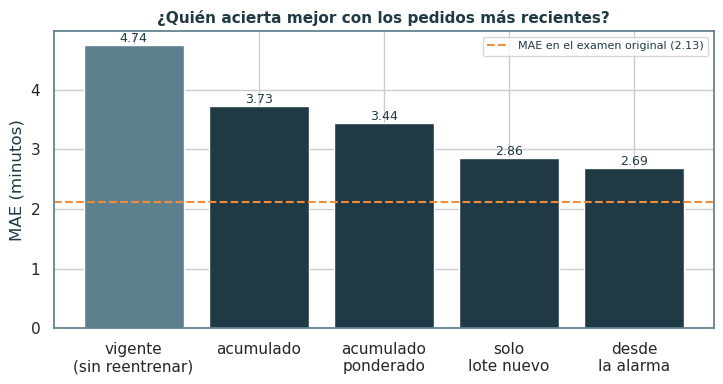

In [10]:
# --- Separación del lote nuevo (drift) por fecha: 80 % para reentrenar, 20 % más reciente para examinar ---
lote_drift = lotes["drift"]
corte_nuevo = fecha_de_corte(lote_drift, FRACCION_REENTRENO)
nuevo_entrenamiento, nuevo_examen = lote_drift[lote_drift["fecha"] < corte_nuevo], lote_drift[lote_drift["fecha"] >= corte_nuevo]
validar(nuevo_entrenamiento["fecha"].max() < nuevo_examen["fecha"].min(), "el examen del lote nuevo es posterior a todo lo que aprenden los candidatos")
print(f"Lote nuevo · para reentrenar: {len(nuevo_entrenamiento):,} pedidos (→ {nuevo_entrenamiento['fecha'].max():%d-%m-%Y}) | examen: {len(nuevo_examen):,} pedidos ({nuevo_examen['fecha'].min():%d-%m-%Y} → {nuevo_examen['fecha'].max():%d-%m-%Y})")

historico = pd.concat([entrenamiento, prueba])        # todo el lote 1: el modelo vigente solo vio el entrenamiento, pero para reentrenar se puede usar entero
CANDIDATOS = {
    "acumulado":           dict(datos=pd.concat([historico, nuevo_entrenamiento]), pesos=None),
    "acumulado ponderado": dict(datos=pd.concat([historico, nuevo_entrenamiento]),
                                pesos=np.r_[np.ones(len(historico)), np.full(len(nuevo_entrenamiento), PESO_LOTE_NUEVO)]),
    "solo lote nuevo":     dict(datos=nuevo_entrenamiento, pesos=None),
    "desde la alarma":     dict(datos=nuevo_entrenamiento[nuevo_entrenamiento["fecha"] >= pd.Period(primer_mes_alarma).start_time], pesos=None),
}

modelos_candidatos, filas = {}, {}
for nombre, cfg in CANDIDATOS.items():
    pipeline = clone(modelo_vigente)                   # MISMO pipeline y ajustes que el vigente, sin entrenar
    pipeline.fit(cfg["datos"][VARIABLES], cfg["datos"][OBJETIVO], **({"modelo__sample_weight": cfg["pesos"]} if cfg["pesos"] is not None else {}))
    modelos_candidatos[nombre] = pipeline
    m_nuevo = D.metricas(nuevo_examen[OBJETIVO], pipeline.predict(nuevo_examen[VARIABLES]))
    m_viejo = D.metricas(prueba[OBJETIVO], pipeline.predict(prueba[VARIABLES]))
    filas[nombre] = {"pedidos_entrenamiento": len(cfg["datos"]), "mae_examen_nuevo": m_nuevo["mae"], "rmse_examen_nuevo": m_nuevo["rmse"],
                     "r2_examen_nuevo": m_nuevo["r2"], "sesgo_examen_nuevo": m_nuevo["sesgo"], "mae_examen_original": m_viejo["mae"]}
    print(f"entrenado: {nombre:20s} MAE en examen nuevo {m_nuevo['mae']:.2f} min")

# El modelo vigente, sin reentrenar, en los mismos exámenes
m_nuevo = D.metricas(nuevo_examen[OBJETIVO], modelo_vigente.predict(nuevo_examen[VARIABLES]))
filas["vigente (sin reentrenar)"] = {"pedidos_entrenamiento": len(entrenamiento), "mae_examen_nuevo": m_nuevo["mae"], "rmse_examen_nuevo": m_nuevo["rmse"],
                                     "r2_examen_nuevo": m_nuevo["r2"], "sesgo_examen_nuevo": m_nuevo["sesgo"], "mae_examen_original": MAE_REF}
comparativa = pd.DataFrame(filas).T.loc[["vigente (sin reentrenar)", *CANDIDATOS]]
display(comparativa)
figura_candidatos(comparativa)
plt.show()

**Cómo elegimos y cuándo se promueve:** el candidato con **menor MAE en el examen nuevo** es el elegido, y solo se **promueve** a modelo vigente si cumple **las dos condiciones** siguientes (si no, se queda como *candidato* y se sigue con el actual):

1. **Mejora de verdad:** baja el MAE al menos un **10 %** frente al modelo vigente en el examen nuevo.
2. **Es un buen modelo para la situación nueva:** su **R²** no es más de 0,05 peor que el de referencia y su **sesgo** no pasa de ±1 minuto (es decir, ya no «se queda corto»).

**¿Por qué R² y sesgo y no solo el MAE?** Después del cambio los pedidos tardan más de media (más platos, más delivery) y el MAE, que se mide en minutos, crece **solo por la escala**, aunque el modelo entienda igual de bien lo que pasa. El R² y el sesgo no dependen de esa escala. Lo vimos al probarlo: exigir que el MAE volviera al valor antiguo bloqueaba un modelo claramente mejor.

El candidato se registra en MLflow como una **versión nueva** del mismo modelo con el alias **`candidato`**. El alias **`actual`** (el que usa la API) **no se toca** salvo que pongas `PROMOVER_AUTOMATICAMENTE = True` en la configuración. Si algún día una versión nueva sale mal, **volver atrás** es mover el alias `actual` a la versión anterior (no hace falta borrar nada).

In [11]:
# --- Elegir el mejor candidato y comprobar las condiciones de promoción ---
mejor = comparativa.loc[list(CANDIDATOS)]["mae_examen_nuevo"].idxmin()
mae_vigente_nuevo = comparativa.loc["vigente (sin reentrenar)", "mae_examen_nuevo"]
mae_mejor = comparativa.loc[mejor, "mae_examen_nuevo"]
mejora = 1 - mae_mejor / mae_vigente_nuevo
cond_mejora = mejora >= MEJORA_MINIMA
r2_mejor, sesgo_mejor = comparativa.loc[mejor, "r2_examen_nuevo"], comparativa.loc[mejor, "sesgo_examen_nuevo"]
cond_normal = (r2_mejor >= R2_REF - TOLERANCIA_R2) and (abs(sesgo_mejor) <= SESGO_MAXIMO)
print(f"Mejor candidato: «{mejor}» · MAE {mae_mejor:.2f} min frente a {mae_vigente_nuevo:.2f} del vigente → mejora del {mejora:.0%}")
print(f"  condición 1 (mejora ≥ {MEJORA_MINIMA:.0%}): {'SÍ' if cond_mejora else 'NO'}")
print(f"  condición 2 (R² {r2_mejor:.3f} ≥ {R2_REF - TOLERANCIA_R2:.3f} y sesgo {sesgo_mejor:+.2f} dentro de ±{SESGO_MAXIMO}): {'SÍ' if cond_normal else 'NO'}")
SE_PROMUEVE = bool(cond_mejora and cond_normal)
validar(mae_mejor < mae_vigente_nuevo, "el mejor candidato acierta más que el modelo vigente con los pedidos más recientes")

Mejor candidato: «desde la alarma» · MAE 2.69 min frente a 4.74 del vigente → mejora del 43%
  condición 1 (mejora ≥ 10%): SÍ
  condición 2 (R² 0.907 ≥ 0.834 y sesgo +0.01 dentro de ±1.0): SÍ
OK · el mejor candidato acierta más que el modelo vigente con los pedidos más recientes


In [12]:
# --- Registrar todo en MLflow: una ejecución con la monitorización y una versión nueva del modelo (alias «candidato») ---
nombre_ejecucion = f"monitorizacion_{MARCA_TIEMPO}"
with mlflow.start_run(run_name=nombre_ejecucion) as ejecucion:
    mlflow.set_tags({"fase": "monitorizacion", "lote_nuevo": LOTES["drift"], "decision": decisiones["drift"].accion,
                     "modelo_vigente": f"{NOMBRE_MODELO} v{version_vigente.version}"})
    mlflow.log_params({"umbral_psi_vigilar": D.PSI_VIGILAR, "umbral_psi_alerta": D.PSI_ALERTA,
                       "umbral_mae_vigilar": D.MAE_VIGILAR, "umbral_mae_alerta": D.MAE_ALERTA,
                       "peso_lote_nuevo": PESO_LOTE_NUEVO, "mejora_minima": MEJORA_MINIMA, "tolerancia_r2": TOLERANCIA_R2,
                       "sesgo_maximo": SESGO_MAXIMO, "mejor_candidato": mejor})
    for clave in lotes:   # métricas de drift de cada lote
        mlflow.log_metrics({f"{clave}_mae": resultados_modelo[clave]["mae"], f"{clave}_r2": resultados_modelo[clave]["r2"],
                            f"{clave}_sesgo": resultados_modelo[clave]["sesgo"], f"{clave}_subida_mae": resultados_modelo[clave]["subida_mae"],
                            f"{clave}_psi_max": float(tablas_drift[clave].query("decide")["psi"].max())})
        mlflow.log_text(tablas_drift[clave].round(4).to_csv(index=False), f"data_drift_{clave}.csv")
        mlflow.log_text(seguimientos[clave].round(4).to_csv(index=False), f"seguimiento_mensual_{clave}.csv")
    mlflow.log_text(comparativa.round(4).to_csv(), "comparativa_candidatos.csv")
    for figura, archivo in [(figura_psi(tablas_drift["drift"], "PSI · lote drift"), "psi_drift.png"),
                            (figura_seguimiento(seguimientos, MAE_REF), "seguimiento_mensual.png"),
                            (figura_candidatos(comparativa), "candidatos.png")]:
        mlflow.log_figure(figura, archivo); plt.close(figura)

    # El candidato elegido, con su firma, y su registro como versión nueva con alias «candidato»
    datos_cand = CANDIDATOS[mejor]["datos"]
    mlflow.log_metrics({"candidato_mae_examen_nuevo": mae_mejor, "vigente_mae_examen_nuevo": mae_vigente_nuevo, "mejora_relativa": mejora})
    firma = infer_signature(datos_cand[VARIABLES].head(100), pd.Series(modelos_candidatos[mejor].predict(datos_cand[VARIABLES].head(100)), name="tiempo_predicho"))
    info = mlflow.sklearn.log_model(modelos_candidatos[mejor], artifact_path="modelo_candidato", signature=firma, input_example=datos_cand[VARIABLES].head(3))
    # Para que la versión guarde su propia nota (el notebook 07 la lee igual que el 06 lee «test_mae»)
    mlflow.log_metrics({"test_mae": mae_mejor, "test_r2": r2_mejor, "test_sesgo": sesgo_mejor})

version_cand = mlflow.register_model(info.model_uri, NOMBRE_MODELO)
cliente.set_registered_model_alias(NOMBRE_MODELO, ALIAS_CANDIDATO, version_cand.version)
cliente.update_model_version(NOMBRE_MODELO, version_cand.version, description=(
    f"Reentrenado el {MARCA_TIEMPO} («{mejor}») tras detectar drift en el lote {LOTES['drift']}. "
    f"Examen con los pedidos más recientes: MAE {mae_mejor:.2f} min (el vigente: {mae_vigente_nuevo:.2f} min)."))
cliente.set_model_version_tag(NOMBRE_MODELO, version_cand.version, "origen", "reentrenamiento_por_drift")
cliente.set_model_version_tag(NOMBRE_MODELO, version_cand.version, "fecha_ejecucion", MARCA_TIEMPO)
print(f"Registrado: '{NOMBRE_MODELO}' versión {version_cand.version} con alias '{ALIAS_CANDIDATO}'.")

if SE_PROMUEVE and PROMOVER_AUTOMATICAMENTE:
    cliente.set_registered_model_alias(NOMBRE_MODELO, ALIAS_VIGENTE, version_cand.version)
    print(f"PROMOVIDO: el alias '{ALIAS_VIGENTE}' apunta ahora a la versión {version_cand.version}. La API usará este modelo en cuanto se reinicie o recargue.")
elif SE_PROMUEVE:
    print(f"El candidato CUMPLE las condiciones. Para promoverlo, una persona debe mover el alias '{ALIAS_VIGENTE}' a la versión {version_cand.version} (MLflow → Models) o poner PROMOVER_AUTOMATICAMENTE = True.")
else:
    print("El candidato NO cumple las condiciones: sigue el modelo actual y se revisará con el siguiente lote.")

Registered model 'smart_restaurant_regresion_tiempo_prep' already exists. Creating a new version of this model...
2026/11/26 08:13:25 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: smart_restaurant_regresion_tiempo_prep, version 3


🏃 View run monitorizacion_2026-11-26_09-12 at: http://mlflow:5000/#/experiments/3/runs/1d1486344c2c4d36ba3355b65a85a9bb
🧪 View experiment at: http://mlflow:5000/#/experiments/3
Registrado: 'smart_restaurant_regresion_tiempo_prep' versión 3 con alias 'candidato'.
El candidato CUMPLE las condiciones. Para promoverlo, una persona debe mover el alias 'actual' a la versión 3 (MLflow → Models) o poner PROMOVER_AUTOMATICAMENTE = True.


Created version '3' of model 'smart_restaurant_regresion_tiempo_prep'.


---
## 8. Estrategia de monitorización y de reentrenamiento

Todo lo anterior se resume en un **proceso repetible**. Los valores concretos (umbrales, frecuencia) son un **punto de partida razonable** que habría que **recalibrar con la experiencia** del restaurante real.

### 8.1 Qué vigilamos, cada cuánto y con qué umbral

| Qué | Cómo | Cuándo | Umbral | Necesita tiempo real |
|---|---|---|---|---|
| **Calidad de captura** | % de filas que la limpieza descarta, duplicados, fechas en formato raro | En cada lote que llega | Más de 3 puntos por encima del lote histórico | No |
| **Data drift** (entradas) | PSI de cada variable contra el entrenamiento | Mensual (y semanal en un restaurante grande) | PSI > 0,10 vigilar · > 0,25 alerta | **No** (alerta temprana) |
| **Model drift** (error) | MAE, RMSE, R² y **sesgo** del modelo vigente | Mensual, cuando ya se conoce el tiempo real de los pedidos | MAE +15 % vigilar · +30 % alerta | Sí |
| **Sesgo del modelo** | Media de *real − predicho* (ya se calcula y se muestra) | Mensual | Orientativo: > +1,5 min varios meses seguidos = el modelo promete menos de lo que tarda. **Todavía no entra en la regla automática**, se revisa a mano | Sí |
| **Variables de contexto** (lluvia) | PSI sobre el lote completo, no mes a mes | Trimestral | Solo informativa (es estacional) | No |

### 8.2 Cuándo se reentrena

1. **Por alarma:** decisión `reentrenar` (MAE +30 %, o 2 o más variables con PSI > 0,25 mientras llega el tiempo real).
2. **Por calendario:** **cada 6 meses** aunque todo esté verde, porque el drift gradual y estacional no siempre cruza los umbrales.
3. **Por evento conocido:** carta nueva, apertura o cierre de un local, cambio de plantilla. **No esperamos a que el modelo falle**: se reentrena en cuanto haya unas semanas de datos con el cambio.

### 8.3 Cómo se reentrena (y por qué es seguro)

- **Mismos pasos que en este notebook:** limpiar el lote con la misma función, comparar cuatro formas de reentrenar con un examen **posterior en el tiempo**, y quedarse con la mejor.
- **Nunca se despliega a ciegas:** el candidato entra con el alias `candidato`. Solo pasa a `actual` si baja el MAE un 10 %, mantiene un R² comparable al de referencia y deja el sesgo casi a cero. **Después de promoverlo, la referencia se reinicia**: el entrenamiento del modelo nuevo pasa a ser la nueva «normalidad» contra la que se comparan los lotes siguientes.
- **Reversible:** la versión anterior sigue en MLflow; volver atrás es mover un alias.
- **Trazable:** cada ejecución guarda en MLflow los umbrales, las tablas de drift, las gráficas y qué lote motivó el cambio.

### 8.4 Qué hace falta para que esto funcione sin mirar el notebook

- Un **lote mensual** que llegue a `data/entrada/<lote>/` y se ingiera con `scripts/ingesta_hdfs.sh` (ya automatizable con el servicio `ingesta` de Docker Compose).
- Guardar la **predicción** que se enseñó a cada cliente junto al tiempo real, para poder medir el MAE sin recalcular nada.
- Una persona responsable de revisar la decisión mensual y de mover el alias `actual`.

### 8.5 Límites de lo que hemos demostrado

- Los dos lotes son **sintéticos** y el cambio del lote *drift* lo hemos programado nosotros: demuestra que el detector funciona, no que los cambios reales vayan a parecerse a este.
- El drift de este ejemplo es **brusco**. El gradual (y mezclado con la estacionalidad) es más difícil: de ahí el reentrenamiento por calendario.
- Solo hemos medido el **Objetivo 2 (regresión)**. El clustering de platos (Objetivo 1) también puede derivar (platos nuevos, cambios de precio), y se vigilaría igual: PSI de `precio_medio`, `coste_medio`, `popularidad`… y reparto de platos por grupo. No lo hemos implementado.
- Los umbrales (PSI 0,10 / 0,25 y MAE +15 % / +30 %) son convenciones habituales, no leyes: hay que ajustarlos al coste real de equivocarse en este negocio.